# 01 生データの目視確認（フェーズ 0）

2026-11-02 に実車で記録した `data/raw/ride_001`〜`ride_009` を読み、列・周波数・値域・時刻・GPS の有効割合を確認する。
結論は `docs/data_schema.md` にまとめた。このノートブックは確認の記録で、処理の本体はフェーズ 1 以降 `src/ct125/` に書く。

**位置情報の扱い**：緯度・経度の実値は表示しない（熊本市周辺の箱に入るかの判定と、最初の fix からの相対距離だけを出す）。

In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams["font.family"] = ["Meiryo", "Yu Gothic", "MS Gothic", "sans-serif"]
plt.rcParams["axes.unicode_minus"] = False
RAW = Path("../data/raw")
KUMAMOTO = dict(lat=(32.5, 33.1), lon=(130.4, 131.2))   # 熊本市周辺のおおまかな箱（判定にだけ使う）

def gps_unix(g):
    d = pd.to_datetime(g["date"].astype(str).str.zfill(6), format="%d%m%y", utc=True)
    u = g["utc"].astype(float)
    sec = (u // 10000) * 3600 + (u // 100 % 100) * 60 + u % 100
    return (d - pd.Timestamp(0, tz="UTC")).dt.total_seconds() + sec

def load(name):
    d = RAW / name
    acc = pd.read_csv(d / "accel.csv")
    gps = pd.read_csv(d / "gps.csv", dtype={"utc": str, "date": str})
    ev = pd.read_csv(d / "events.csv")
    st = pd.read_csv(d / "status.csv")
    meta = json.loads((d / "meta.json").read_text(encoding="utf-8"))
    memo = " ".join(p.read_text(encoding="utf-8").strip() for p in d.glob("*.txt"))
    acc["t_rel"] = (acc.t_us - acc.t_us.iloc[0]) / 1e6
    acc["mag_g"] = np.sqrt(acc.ax_g**2 + acc.ay_g**2 + acc.az_g**2)
    gps["t_rel"] = (gps.t_rx_us - acc.t_us.iloc[0]) / 1e6
    gv = gps[gps.status == "A"]
    offset = float(np.median(gps_unix(gv) - gv.t_rx_us / 1e6)) if len(gv) else None
    if offset is not None:
        for df, col in ((acc, "t_us"), (gps, "t_rx_us")):
            df["jst"] = pd.to_datetime(df[col] / 1e6 + offset, unit="s", utc=True).dt.tz_convert("Asia/Tokyo").dt.tz_localize(None)
    return dict(name=name, acc=acc, gps=gps, events=ev, status=st, meta=meta, memo=memo, offset=offset)

RIDES = [f"ride_{i:03d}" for i in range(1, 10)]

## 1. 9 本の棚卸し（行数・周波数・欠け・GPS 有効割合）

In [2]:
rows = []
for name in RIDES:
    r = load(name); acc, gps, st = r["acc"], r["gps"], r["status"]
    dt = np.diff(acc.t_us); dur = (acc.t_us.iloc[-1] - acc.t_us.iloc[0]) / 1e6
    gv = gps[gps.status == "A"]
    first10 = acc[acc.t_rel < 10]
    rows.append(dict(
        ride=name, memo=r["memo"][:28], min=round(dur / 60, 1), acc_rows=len(acc),
        fs_hz=round((len(acc) - 1) / dur, 1), dt_min_us=int(dt.min()), dt_max_us=int(dt.max()),
        n_gaps=int((np.diff(acc.n) != 1).sum()), t_dup=int((dt == 0).sum()), monotonic=bool((dt > 0).all()),
        clip_rows=int((acc[["ax_g", "ay_g", "az_g"]].abs() >= 15.9).any(axis=1).sum()),
        mag_med=round(float(acc.mag_g.median()), 3), mag_p99=round(float(acc.mag_g.quantile(0.99)), 2), mag_max=round(float(acc.mag_g.max()), 1),
        g0=tuple(first10[["ax_g", "ay_g", "az_g"]].mean().round(2)),
        gps_rows=len(gps), gps_fix_ratio=round(len(gv) / len(gps), 3),
        sats=f"{int(gv.sats.min())}-{int(gv.sats.max())}" if len(gv) else "0",
        first_fix_s=round(float(gv.t_rel.iloc[0]), 1) if len(gv) else None,
        jst_start=acc.jst.iloc[0].strftime("%m-%d %H:%M:%S") if "jst" in acc else None,
        in_kumamoto=round(float((gv.lat.between(*KUMAMOTO["lat"]) & gv.lon.between(*KUMAMOTO["lon"])).mean()), 2) if len(gv) else None,
        events=",".join(r["events"].type.tolist()[1:]) or "-",
        errors=int(st[["ring_drops", "fifo_overruns", "i2c_errors", "sd_write_errors", "time_resyncs"]].iloc[-1].sum()),
    ))
summary = pd.DataFrame(rows).set_index("ride")
pd.set_option("display.width", 250, "display.max_columns", 50)
summary

,memo,min,acc_rows,fs_hz,dt_min_us,dt_max_us,n_gaps,t_dup,monotonic,clip_rows,mag_med,mag_p99,mag_max,g0,gps_rows,gps_fix_ratio,sats,first_fix_s,jst_start,in_kumamoto,events,errors
ride,,,,,,,,,,,,,,,,,,,,,,
ride_001,これはアイドリングのデータが入っている,2.0,48004,399.1,2479,2539,0,0,True,0,0.956,1.10,9.8,"(0.19, 0.85, -0.4)",120,0.700,6-13,36.9,11-02 13:35:25,1.0,gps_valid,0
ride_002,ride1と同様にサイドスタンドで斜めになった状態でアイ,2.3,56004,399.0,2489,2543,0,0,True,0,0.959,3.04,9.9,"(0.19, 0.85, -0.4)",140,0.886,13-16,17.2,11-02 13:42:09,1.0,gps_valid,0
ride_003,センタースタンドからセンタースタンドをはずして垂直になっ,1.5,35200,398.8,2480,2544,0,0,True,0,0.965,1.62,11.1,"(0.19, 0.85, -0.4)",88,0.977,7-16,3.0,11-02 13:48:52,1.0,gps_valid,0
ride_004,実際に走行。自宅から歯医者まで,13.9,332408,398.2,2479,2549,0,0,True,0,1.040,3.33,11.8,"(0.23, 0.83, -0.41)",834,0.953,3-17,36.7,11-02 14:03:38,1.0,"gps_valid,gps_lost,gps_valid",0
ride_005,実際に走行。歯医者から自宅まで,15.3,364344,397.5,2493,2592,0,0,True,0,1.030,2.62,11.4,"(0.21, 0.86, -0.4)",916,0.900,3-18,32.4,11-02 14:52:58,1.0,"gps_valid,gps_lost,gps_valid",0
ride_006,,1.7,39600,398.5,2489,2548,0,0,True,0,0.945,0.97,1.1,"(0.11, 0.84, -0.42)",99,0.000,0,NaN,NaN,NaN,-,0
ride_007,,37.4,895204,399.0,2489,2549,0,0,True,1,1.141,6.29,18.5,"(0.11, 0.84, -0.42)",2244,0.000,0,NaN,NaN,NaN,-,0
ride_008,,6.9,165200,398.3,2489,2541,0,0,True,0,1.034,2.82,16.4,"(0.1, 0.96, -0.24)",415,0.000,0,NaN,NaN,NaN,-,0
ride_009,,31.1,746312,400.2,2458,2542,0,0,True,0,1.105,7.15,17.1,"(0.13, 0.98, -0.19)",1865,0.000,0,NaN,NaN,NaN,-,0


- 9 本とも `n` の飛び・`t_us` の重複なし、`events.csv`／`status.csv` のエラー系は 0。実測 fs は 397.5〜400.2 Hz（設定 400 Hz）。
- ride_001〜005 は GPS あり（起動後 4〜38 秒で初回 fix）。ride_006〜009 は先頭から最後まで衛星 0。
- 有効な座標はすべて熊本市周辺の箱に入る（`in_kumamoto=1.0`）。

## 2. 列・型・先頭 5 行（ride_004）

In [3]:
r4 = load("ride_004")
print(r4["meta"])
display(r4["acc"][["n", "t_us", "ax_g", "ay_g", "az_g"]].head())
print(r4["acc"][["n", "t_us", "ax_g", "ay_g", "az_g"]].dtypes.to_dict())
# gps.csv：先頭は測位前（status=V、lat/lon は空）。lat/lon 列は常にマスクして表示する
g = r4["gps"].drop(columns=["t_rel", "jst"], errors="ignore").copy()
g[["lat", "lon"]] = g[["lat", "lon"]].notna().map(lambda b: "(値あり)" if b else "")
display(g.head())
print(r4["gps"].drop(columns=["t_rel", "jst"], errors="ignore").dtypes.to_dict())
display(r4["events"]); display(r4["status"].head(3))

{'spec': 'データ仕様.md v2', 'firmware': 'CT125_LOGGER_V2.1', 'build': 'Nov  2 2026 01:16:33', 'clock': 't_us = ESP32 esp_timer（起動からのマイクロ秒）', 'accel': {'chip': 'ADXL345', 'odr_hz': 400, 'range_g': 16, 'lsb_g': 0.0039, 'unit': 'g', 'axes': 'センサー基板の軸のまま'}, 'gps': {'chip': 'ATGM336H', 'baud': 9600, 't_rx_us': 'RMC文の先頭を受け取った時刻', 'pps_pin': -1}, 'mounting': '未記入（取り付けたら notes.md に書く）', 'flush_ms': 1000}


,n,t_us,ax_g,ay_g,az_g
0,0,776927,0.2223,0.8346,-0.4251
1,1,779427,0.2340,0.8385,-0.4134
2,2,781927,0.2301,0.8268,-0.4095
3,3,784427,0.2379,0.8268,-0.4095
4,4,786906,0.2379,0.8112,-0.4251


{'n': dtype('int64'), 't_us': dtype('int64'), 'ax_g': dtype('float64'), 'ay_g': dtype('float64'), 'az_g': dtype('float64')}


,t_rx_us,utc,date,status,fix,sats,hdop,lat,lon,speed_kmh,course_deg
0,1222982,NaN,NaN,V,0,0,25.5,,,NaN,NaN
1,2231934,NaN,NaN,V,0,0,25.5,,,NaN,NaN
2,3231934,NaN,NaN,V,0,0,25.5,,,NaN,NaN
3,4231033,NaN,NaN,V,0,0,25.5,,,NaN,NaN
4,5239009,NaN,NaN,V,0,0,25.5,,,NaN,NaN


{'t_rx_us': dtype('int64'), 'utc': <StringDtype(na_value=nan)>, 'date': <StringDtype(na_value=nan)>, 'status': <StringDtype(na_value=nan)>, 'fix': dtype('int64'), 'sats': dtype('int64'), 'hdop': dtype('float64'), 'lat': dtype('float64'), 'lon': dtype('float64'), 'speed_kmh': dtype('float64'), 'course_deg': dtype('float64')}


,t_us,type,detail
0,316864,boot,CT125_LOGGER_V2.1
1,37562872,gps_valid,NaN
2,799243885,gps_lost,NaN
3,802388648,gps_valid,NaN


,t_us,samples,rate_hz,ring_drops,fifo_overruns,i2c_errors,sd_write_errors,bytes,gps_status,gps_sats,period_us,dt_min_us,dt_max_us,pll_err_max_us,time_resyncs
0,10780631,3984,398.28,0,0,0,0,138821,V,0,2511.11,2479,2549,2185,0
1,20782624,7968,398.29,0,0,0,0,282657,V,12,2510.81,2493,2534,1170,0
2,30786621,11952,398.29,0,0,0,0,428473,V,15,2510.82,2493,2534,1165,0


## 3. 加速度のサンプリング間隔（PLL 方式の確認）

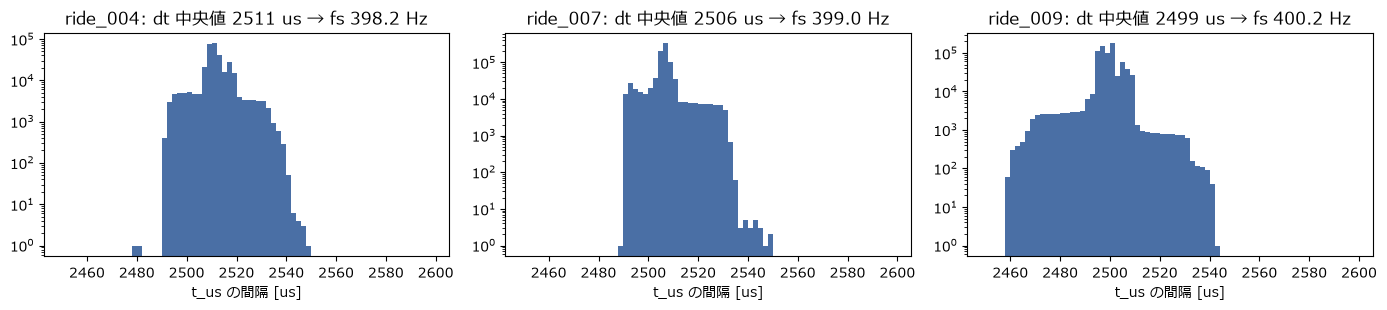

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.2))
for ax, name in zip(axes, ["ride_004", "ride_007", "ride_009"]):
    acc = load(name)["acc"]; dt = np.diff(acc.t_us)
    ax.hist(dt, bins=np.arange(2450, 2600, 2), color="#4a6fa5")
    ax.set_title(f"{name}: dt 中央値 {np.median(dt):.0f} us → fs {1e6/np.median(dt):.1f} Hz")
    ax.set_xlabel("t_us の間隔 [us]"); ax.set_yscale("log")
plt.tight_layout()

間隔は 2,460〜2,590 us にほぼそろう（V2 以前の 2 ms／3 ms 割れはない）。1 秒窓の中では等間隔として扱って問題ない。

## 4. 加速度の値域・重力・振り切れ

|axis| >= 15.9 g のサンプル数: {'ride_001': 0, 'ride_002': 0, 'ride_003': 0, 'ride_004': 0, 'ride_005': 0, 'ride_006': 0, 'ride_007': 1, 'ride_008': 0, 'ride_009': 0}
ride_007 で |axis| >= 15 g のサンプル数（軸別）: {'ax_g': 25, 'ay_g': 0, 'az_g': 0}


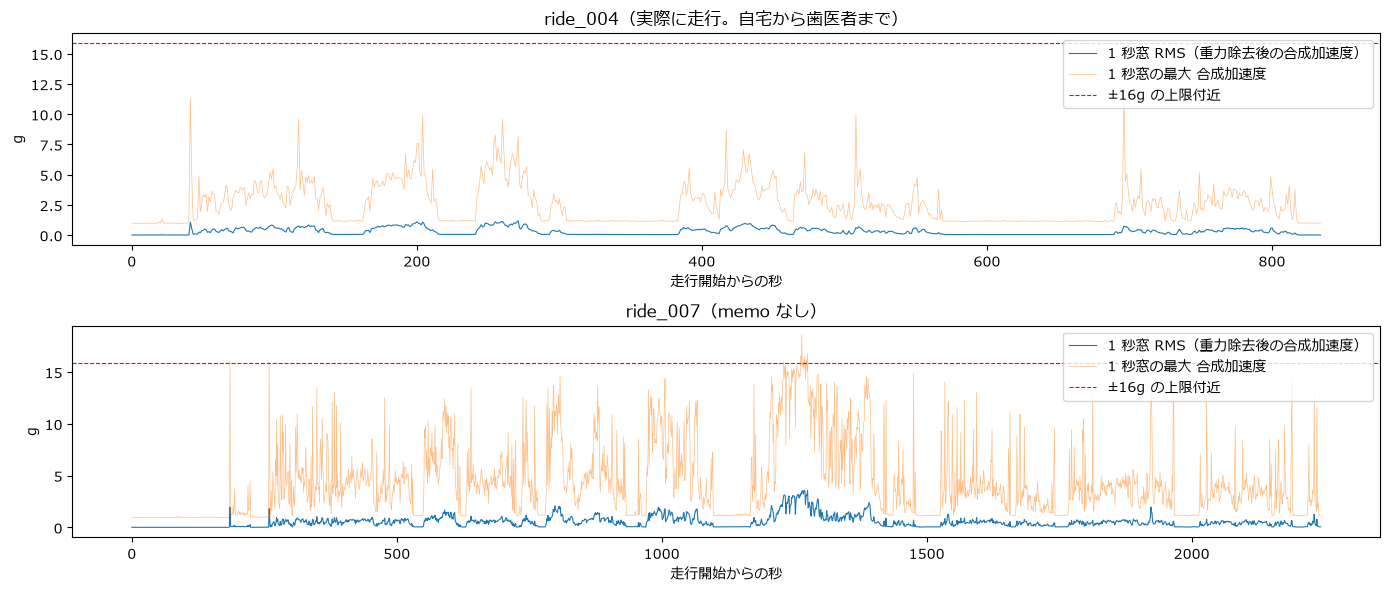

In [5]:
fig, axes = plt.subplots(2, 1, figsize=(14, 6), sharex=False)
for ax, name in zip(axes, ["ride_004", "ride_007"]):
    r = load(name); acc = r["acc"]
    w = acc.groupby((acc.t_rel // 1).astype(int))
    rms = w.mag_g.apply(lambda s: np.sqrt(((s - s.mean())**2).mean()))
    mx = w.mag_g.max()
    ax.plot(rms.index, rms.values, lw=0.8, label="1 秒窓 RMS（重力除去後の合成加速度）")
    ax.plot(mx.index, mx.values, lw=0.5, alpha=0.5, label="1 秒窓の最大 合成加速度")
    ax.axhline(15.9, color="r", ls="--", lw=0.8, label="±16g の上限付近")
    ax.set_title(f"{name}（{r['memo'] or 'memo なし'}）"); ax.set_xlabel("走行開始からの秒"); ax.set_ylabel("g"); ax.legend(loc="upper right")
plt.tight_layout()
clip = {n: int((load(n)["acc"][["ax_g", "ay_g", "az_g"]].abs() >= 15.9).sum().sum()) for n in RIDES}
print("|axis| >= 15.9 g のサンプル数:", clip)
a7 = load("ride_007")["acc"]
print("ride_007 で |axis| >= 15 g のサンプル数（軸別）:", (a7[["ax_g", "ay_g", "az_g"]].abs() >= 15).sum().to_dict())

- 単位は g で重力込み。静止時の合成加速度は 0.95〜0.97 g（1 g より数 % 小さいのは ADXL345 のオフセット・感度の個体差。相対的な振動量の評価には影響しない）。
- 振り切れは ride_007 の X 軸で 1 サンプル（15.9 g）、15 g 以上が 25 サンプル。他は 0。郊外走行で X 軸が上限に近づくので、フェーズ 1 で `is_clipped` を付ける。
- 静止 10 秒の重力の向きは Y 軸が主（ay ≈ +0.85 g、az ≈ −0.4 g）。ride_008/009 は向きが変わっている（表 1 の `g0`）。

## 5. GPS：有効割合、品質、速度（ride_004 / ride_005）

ride_004 status x fix:
fix      0    1  6
status            
A        0  793  2
V       17   21  1
ride_005 status x fix:
fix      0    1  6
status            
A        0  823  1
V       79   12  1


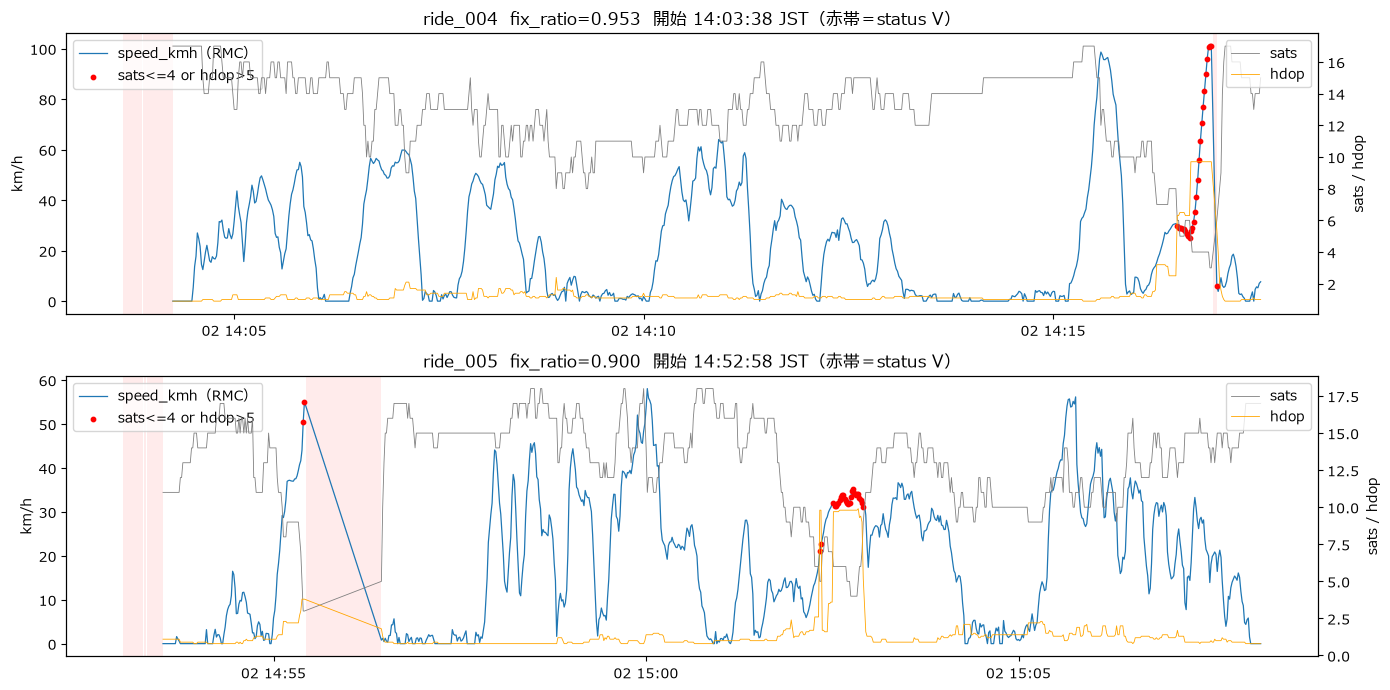

In [6]:
fig, axes = plt.subplots(2, 1, figsize=(14, 7))
for ax, name in zip(axes, ["ride_004", "ride_005"]):
    r = load(name); g = r["gps"]; gv = g[g.status == "A"]
    ax.plot(gv.jst, gv.speed_kmh, lw=0.9, label="speed_kmh（RMC）")
    ax2 = ax.twinx(); ax2.plot(gv.jst, gv.sats, color="gray", lw=0.6, label="sats"); ax2.plot(gv.jst, gv.hdop, color="orange", lw=0.6, label="hdop")
    lost = g[g.status == "V"]
    for t in lost.jst: ax.axvspan(t, t + pd.Timedelta(seconds=1), color="red", alpha=0.08, lw=0)
    bad = gv[(gv.sats <= 4) | (gv.hdop > 5)]
    ax.scatter(bad.jst, bad.speed_kmh, color="red", s=10, zorder=3, label="sats<=4 or hdop>5")
    ax.set_title(f"{name}  fix_ratio={len(gv)/len(g):.3f}  開始 {r['acc'].jst.iloc[0]:%H:%M:%S} JST（赤帯＝status V）")
    ax.set_ylabel("km/h"); ax2.set_ylabel("sats / hdop"); ax.legend(loc="upper left"); ax2.legend(loc="upper right")
plt.tight_layout()
for name in ["ride_004", "ride_005"]:
    g = load(name)["gps"]
    print(name, "status x fix:")
    print(pd.crosstab(g.status, g.fix.fillna(-1).astype(int)).to_string())

- ride_004 14:16:30〜55 は衛星 3〜6・HDOP 6〜9.7 のまま速度が 29→101 km/h まで単調に増え、直後に `gps_lost`。誤測位として扱い、この区間の速度・座標は使わない。
- ride_005 14:55:23〜24 も衛星 3 で 50〜55 km/h、直後に 61 秒の `gps_lost`。15:02:19〜54 は HDOP 9〜10 が続く。
- `status=A` でも `fix=6`（推定）の行が 1〜2 行ある。有効判定は `status`、品質フィルタは `sats ≥ 5 かつ hdop ≤ 5` で行う（`docs/data_schema.md` 6.）。

## 6. 軌跡の形（最初の fix からの相対距離。緯度経度の実値は出さない）

In [7]:
fig, ax = plt.subplots(figsize=(6, 6))
origin = None
for name, c in [("ride_004", "#1f77b4"), ("ride_005", "#d62728")]:
    g = load(name)["gps"]; gv = g[(g.status == "A") & (g.sats >= 5) & (g.hdop <= 5)]
    if origin is None: origin = (gv.lat.iloc[0], gv.lon.iloc[0])
    x = (gv.lon - origin[1]) * 111320 * np.cos(np.deg2rad(origin[0])); y = (gv.lat - origin[0]) * 110540
    ax.plot(x, y, ".", ms=2, color=c, label=f"{name}（品質フィルタ後 {len(gv)} 点）")
ax.set_aspect("equal"); ax.set_xlabel("東西 [m]（ride_004 の最初の fix を 0）"); ax.set_ylabel("南北 [m]"); ax.legend(); ax.grid(alpha=0.3)
ax.set_title("ride_004（往路）と ride_005（復路）")
plt.tight_layout()

## 7. GPS なし走行の確認（ride_006〜009）

In [8]:
for name in ["ride_006", "ride_007", "ride_008", "ride_009"]:
    g = load(name)["gps"]
    print(name, f"rows={len(g)} status_A={int((g.status == 'A').sum())} sats_max={int(g.sats.max())} utc_rows={int(g.utc.notna().sum())} hdop_unique={sorted(g.hdop.unique())}")

ride_006 rows=99 status_A=0 sats_max=0 utc_rows=0 hdop_unique=[np.float64(25.5)]
ride_007 rows=2244 status_A=0 sats_max=0 utc_rows=0 hdop_unique=[np.float64(25.5)]
ride_008 rows=415 status_A=0 sats_max=0 utc_rows=0 hdop_unique=[np.float64(25.5)]
ride_009 rows=1865 status_A=0 sats_max=0 utc_rows=0 hdop_unique=[np.float64(25.5)]


4 本とも全行 `status=V`、衛星 0、`utc` なし（時刻すら受信していない）。直前の ride_005 は 33 秒で測位できているので、
コールドスタートの待ち時間ではなく、受信そのものができていない（アンテナの遮蔽、または GPS TX 線の接触）可能性が高い。

## 8. 時刻の同期（t_us と UTC の対応のばらつき）

In [9]:
for name in RIDES[:5]:
    g = load(name)["gps"]; gv = g[g.status == "A"]
    off = gps_unix(gv) - gv.t_rx_us / 1e6
    print(f"{name}: offset 中央値 {np.median(off):.3f} s, 標準偏差 {off.std()*1e3:.1f} ms, 範囲 {(off.max()-off.min())*1e3:.0f} ms, 有効行 {len(gv)}")

ride_001: offset 中央値 1793594124.316 s, 標準偏差 56.0 ms, 範囲 222 ms, 有効行 84
ride_002: offset 中央値 1793594529.038 s, 標準偏差 37.4 ms, 範囲 196 ms, 有効行 124


ride_003: offset 中央値 1793594932.160 s, 標準偏差 18.2 ms, 範囲 104 ms, 有効行 86
ride_004: offset 中央値 1793595817.598 s, 標準偏差 40.2 ms, 範囲 249 ms, 有効行 795
ride_005: offset 中央値 1793598777.824 s, 標準偏差 44.3 ms, 範囲 274 ms, 有効行 824


ばらつきは数十 ms（NMEA の送信遅れ）。1 秒窓の解析には十分で、PPS は今回不要。

## まとめ（`docs/data_schema.md` に反映済み）

| 項目 | 結果 |
|---|---|
| 列 | `accel.csv`: `n,t_us,ax_g,ay_g,az_g` ／ `gps.csv`: `t_rx_us,utc,date,status,fix,sats,hdop,lat,lon,speed_kmh,course_deg` |
| 単位・周波数 | g（重力込み、±16 g）、実測 約 398.5 Hz |
| 時刻基準 | `t_us`（ESP32 起動からの us）。GPS 有効行から UTC へのオフセットを求めて JST を付ける。GPS なしは相対時間のみ |
| GPS 有効割合 | ride_004: 0.95、ride_005: 0.90、ride_006〜009: 0.00 |
| 欠け・エラー | なし（9 本とも） |
| 要注意 | ride_004 の 100 km/h 区間と ride_005 の 55 km/h 区間は低品質測位。ride_007 で X 軸 15.9 g が 1 回 |